<a href="https://colab.research.google.com/github/mohithkumarreddyputtur-sketch/DEEP-LEARINING-/blob/main/Experiment_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


clipnorm None loss [1.049083948135376, 0.04028456658124924, 0.006580010522156954]
clipnorm 1.0 loss [0.9606384038925171, 0.03664403408765793, 0.005906347651034594]
clipnorm 5.0 loss [1.275046467781067, 0.07480550557374954, 0.009418731555342674]


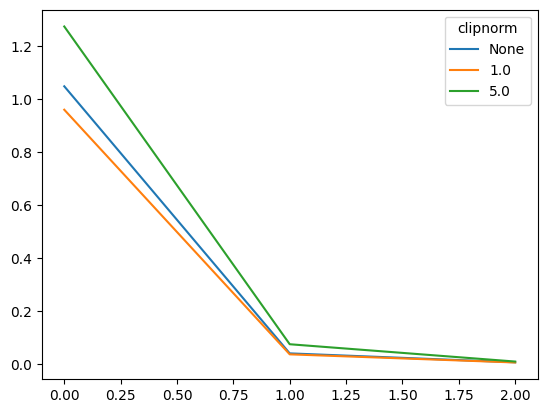

In [1]:
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt
text='deep learning sequence modeling gradient clipping ' * 200
chars=sorted(set(text)); idx={c:i for i,c in enumerate(chars)}; data=np.array([idx[c] for c in text])
X=np.array([data[i:i+20] for i in range(len(data)-21)]); y=data[20:len(data)-1]
X=tf.one_hot(X,len(chars)); y=tf.one_hot(y,len(chars))
for clip in [None,1.0,5.0]:
 m=tf.keras.Sequential([tf.keras.layers.SimpleRNN(32,input_shape=(20,len(chars))),tf.keras.layers.Dense(len(chars),activation='softmax')])
 opt=tf.keras.optimizers.Adam(learning_rate=.03,clipnorm=clip); m.compile(opt,'categorical_crossentropy')
 h=m.fit(X[:1000],y[:1000],epochs=3,batch_size=32,verbose=0); print('clipnorm',clip,'loss',h.history['loss'])
 plt.plot(h.history['loss'],label=str(clip))
plt.legend(title='clipnorm'); plt.show()